# BCSC 多径稳定性置信度：扰动 Bootstrap

目标记录：`010 | Voyage_Ori_01 / PulseTrain_014 / Click_008`

本 Notebook **独立于原 BCSC Notebook**，不修改原算法文件。它先重新计算参考 BCSC 分解，再进行 100 次扰动 Bootstrap：

1. 对参考分解残差实施循环移动块重采样，保留短时相关结构；
2. 将正则强度在参考值的 ±15% 内随机扰动；
3. 将原子时长限制在 20–150 μs 内，并在该范围均匀随机扰动；
4. 每次原子更新后进行频域硬投影，使原子的实测 −3 dB带宽数值处于6–72 kHz；
5. 若候选相对延迟落在参考路径 ±0.03 ms 内，则判定该路径在本轮重现。

$$C_k=\frac{1}{B}\sum_{b=1}^{B}\mathbf{1}\{\text{第 }k\text{ 条路径在第 }b\text{ 轮重现}\}.$$

这里的 $C_k$ 是**扰动稳定性置信度（检出率）**，不是该候选为真实物理多径的后验概率。延迟和幅度的 95% 区间均为“条件于该路径被检出”的 Bootstrap 百分位区间。

In [1]:
from pathlib import Path
import csv
import json
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, fftconvolve, correlate, find_peaks, windows

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None):
        print(desc or "处理中……")
        return iterable

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

PROJECT_ROOT = Path(r"D:\Project_Github\Indo-Pacific-humpback-dolphin")
INPUT_WAV = PROJECT_ROOT / r"00_Data\Positive_Clicks_3500\Voyage_Ori_01\PulseTrain_014\Click_008\Pulse_008.wav"
OUTPUT_DIR = PROJECT_ROOT / r"18_多径提取算法\BCSC_010_bootstrap_confidence_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 与原 Notebook 一致的参考参数
LOWCUT_HZ = 20_000.0
HIGHCUT_HZ = 190_000.0
REFERENCE_ATOM_MS = 0.085  # 85 μs，位于20–150 μs约束区间中点
OUTER_ITERATIONS = 35
FISTA_ITERATIONS = 120
DICTIONARY_ITERATIONS = 30
REFERENCE_LAMBDA_RATIO = 0.075
MIN_PATH_DISTANCE_MS = 0.035
PEAK_RATIO = 0.015

# Bootstrap 默认设置
N_BOOTSTRAP = 100
LAMBDA_PERTURBATION = 0.15
ATOM_DURATION_RANGE_MS = (0.020, 0.150)  # 20–150 μs
MATCH_TOLERANCE_MS = 0.03
RESIDUAL_BLOCK_MS = 0.10
MIN_3DB_BANDWIDTH_HZ = 6_000.0
MAX_3DB_BANDWIDTH_HZ = 72_000.0
BANDWIDTH_NFFT = 16_384
RANDOM_SEED = 20260813

print(f"输入：{INPUT_WAV}")
print(f"输出：{OUTPUT_DIR}")
print(f"Bootstrap 次数：{N_BOOTSTRAP}")


输入：D:\Project_Github\Indo-Pacific-humpback-dolphin\00_Data\Positive_Clicks_3500\Voyage_Ori_01\PulseTrain_014\Click_008\Pulse_008.wav
输出：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results
Bootstrap 次数：100


## 1. 读取与预处理

使用与原 BCSC Notebook 相同的 20–190 kHz 零相位带通滤波和幅度归一化。

In [2]:
def to_float_audio(data):
    if np.issubdtype(data.dtype, np.integer):
        info = np.iinfo(data.dtype)
        return data.astype(np.float64) / max(abs(info.min), info.max)
    return data.astype(np.float64)


def preprocess_click(path, lowcut_hz=20_000.0, highcut_hz=190_000.0):
    sample_rate, raw = wavfile.read(path)
    raw = to_float_audio(raw)
    if raw.ndim == 2:
        raw = raw.mean(axis=1)
    raw = raw - np.mean(raw)
    nyquist = sample_rate / 2.0
    sos = butter(5, [lowcut_hz / nyquist, highcut_hz / nyquist], btype="bandpass", output="sos")
    filtered = sosfiltfilt(sos, raw)
    filtered *= windows.tukey(len(filtered), alpha=0.04)
    scale = np.max(np.abs(filtered)) + np.finfo(float).eps
    return sample_rate, raw, filtered / scale


fs, raw, y = preprocess_click(INPUT_WAV, LOWCUT_HZ, HIGHCUT_HZ)
t_ms = np.arange(len(y)) / fs * 1e3
print(f"采样率：{fs:,} Hz；样本数：{len(y):,}；时长：{len(y) / fs * 1e3:.3f} ms")


采样率：576,000 Hz；样本数：5,761；时长：10.002 ms


## 2. BCSC 与路径读取函数

稀疏编码使用 FISTA，原子使用投影梯度更新；每次更新后对原子频谱进行硬投影，并重新检查实测 −3 dB带宽。为了避免 Bootstrap 样本中偶发的前置噪声峰被误标成直达径，路径延迟统一相对于**最大绝对稀疏系数对应的主到达**计算。

In [3]:
def soft_threshold(z, threshold):
    return np.sign(z) * np.maximum(np.abs(z) - threshold, 0.0)


def reconstruct(atom, activation, signal_len):
    return fftconvolve(activation, atom, mode="full")[:signal_len]


def adjoint_atom(residual, atom, activation_len):
    return correlate(residual, atom, mode="valid", method="fft")[:activation_len]


def adjoint_code(residual, activation, atom_length):
    return correlate(residual, activation, mode="valid", method="fft")[:atom_length]


def spectral_lipschitz(kernel, output_len):
    n_fft = 1 << int(np.ceil(np.log2(output_len)))
    return float(np.max(np.abs(np.fft.rfft(kernel, n=n_fft)) ** 2) + 1e-10)


def normalize_atom(atom):
    atom = np.asarray(atom, dtype=float) - np.mean(atom)
    norm = np.linalg.norm(atom)
    if norm < 1e-12:
        raise RuntimeError("原子范数接近 0。")
    atom = atom / norm
    if atom[np.argmax(np.abs(atom))] < 0:
        atom = -atom
    return atom


def measure_3db_bandwidth(atom, sample_rate, n_fft=16_384):
    """测量绝对主谱峰所在连续 −3 dB频带的宽度。"""
    spectrum = np.abs(np.fft.rfft(atom, n=n_fft))
    frequencies = np.fft.rfftfreq(n_fft, d=1.0 / sample_rate)
    peak_index = int(np.argmax(spectrum))
    threshold = spectrum[peak_index] / np.sqrt(2.0)

    left = peak_index
    while left > 0 and spectrum[left - 1] >= threshold:
        left -= 1
    right = peak_index
    while right < len(spectrum) - 1 and spectrum[right + 1] >= threshold:
        right += 1

    def crossing(i_below, i_above):
        f0, f1 = frequencies[i_below], frequencies[i_above]
        m0, m1 = spectrum[i_below], spectrum[i_above]
        if abs(m1 - m0) < 1e-15:
            return float(f1)
        return float(f0 + (threshold - m0) * (f1 - f0) / (m1 - m0))

    if left == 0:
        left_frequency = 0.0
    else:
        left_frequency = crossing(left - 1, left)
    if right == len(spectrum) - 1:
        right_frequency = sample_rate / 2.0
    else:
        right_frequency = crossing(right + 1, right)
    return float(max(0.0, right_frequency - left_frequency)), float(frequencies[peak_index])


def hard_project_3db_bandwidth(atom, sample_rate, min_bandwidth_hz=6_000.0,
                               max_bandwidth_hz=72_000.0, n_fft=16_384,
                               max_projection_iterations=12):
    """用以主谱峰为中心的高斯频谱包络执行硬投影，并验证最终带宽。"""
    projected = normalize_atom(atom)
    bandwidth, center_frequency = measure_3db_bandwidth(projected, sample_rate, n_fft)
    if min_bandwidth_hz <= bandwidth <= max_bandwidth_hz:
        return projected

    target = float(np.clip(bandwidth, min_bandwidth_hz, max_bandwidth_hz))
    frequencies = np.fft.rfftfreq(n_fft, d=1.0 / sample_rate)
    taper = windows.tukey(len(projected), alpha=0.20)

    for _ in range(max_projection_iterations):
        spectrum = np.fft.rfft(projected, n=n_fft)
        phase = np.angle(spectrum)
        magnitude = np.abs(spectrum)
        peak_index = int(np.argmax(magnitude))
        center_frequency = float(frequencies[peak_index])

        # 对高斯幅度谱，±target/2 处正好下降到峰值的 1/sqrt(2)。
        sigma = max(target / (2.0 * np.sqrt(np.log(2.0))), frequencies[1])
        envelope = np.exp(-0.5 * ((frequencies - center_frequency) / sigma) ** 2)
        constrained_spectrum = envelope * np.exp(1j * phase)
        candidate = np.fft.irfft(constrained_spectrum, n=n_fft)[:len(projected)]
        projected = normalize_atom(candidate * taper)
        bandwidth, _ = measure_3db_bandwidth(projected, sample_rate, n_fft)
        if min_bandwidth_hz <= bandwidth <= max_bandwidth_hz:
            return projected
        if bandwidth < min_bandwidth_hz:
            target *= 1.05 * min_bandwidth_hz / max(bandwidth, 1.0)
        else:
            target *= 0.95 * max_bandwidth_hz / bandwidth
        target = float(np.clip(target, 1_000.0, sample_rate * 0.80))

    bandwidth, _ = measure_3db_bandwidth(projected, sample_rate, n_fft)
    raise RuntimeError(
        f"频域硬投影未能满足 −3 dB带宽约束：{bandwidth / 1e3:.2f} kHz"
    )


def initialize_atom(signal, atom_length):
    peak = int(np.argmax(np.abs(signal)))
    half = atom_length // 2
    padded = np.pad(signal, (half, half))
    atom = padded[peak:peak + atom_length].copy()
    atom = normalize_atom(atom * windows.tukey(atom_length, alpha=0.35))
    return hard_project_3db_bandwidth(
        atom, fs, MIN_3DB_BANDWIDTH_HZ, MAX_3DB_BANDWIDTH_HZ, BANDWIDTH_NFFT
    )


def fista_sparse_code(signal, atom, lam, x0=None, n_iter=120):
    activation_len = len(signal) - len(atom) + 1
    x = np.zeros(activation_len) if x0 is None else x0.copy()
    z = x.copy()
    momentum = 1.0
    lipschitz = spectral_lipschitz(atom, len(signal))
    for _ in range(n_iter):
        residual = reconstruct(atom, z, len(signal)) - signal
        gradient = adjoint_atom(residual, atom, activation_len)
        x_new = soft_threshold(z - gradient / lipschitz, lam / lipschitz)
        momentum_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * momentum * momentum))
        z = x_new + ((momentum - 1.0) / momentum_new) * (x_new - x)
        x, momentum = x_new, momentum_new
    return x


def update_atom(signal, activation, atom, n_iter=30):
    if np.linalg.norm(activation) < 1e-12:
        return atom
    step = 0.8 / spectral_lipschitz(activation, len(signal))
    updated = atom.copy()
    taper = windows.tukey(len(atom), alpha=0.20)
    for _ in range(n_iter):
        residual = reconstruct(updated, activation, len(signal)) - signal
        gradient = adjoint_code(residual, activation, len(atom))
        updated = normalize_atom((updated - step * gradient) * taper)
        updated = hard_project_3db_bandwidth(
            updated, fs, MIN_3DB_BANDWIDTH_HZ, MAX_3DB_BANDWIDTH_HZ, BANDWIDTH_NFFT
        )
    return updated


def shift_atom_and_code(atom, activation):
    center = len(atom) // 2
    shift = center - int(np.argmax(np.abs(atom)))
    shifted_atom = np.roll(atom, shift)
    if shift > 0:
        shifted_atom[:shift] = 0.0
    elif shift < 0:
        shifted_atom[shift:] = 0.0
    shifted_atom = normalize_atom(shifted_atom)
    shifted_atom = hard_project_3db_bandwidth(
        shifted_atom, fs, MIN_3DB_BANDWIDTH_HZ, MAX_3DB_BANDWIDTH_HZ, BANDWIDTH_NFFT
    )
    shifted_code = np.roll(activation, -shift)
    if shift > 0:
        shifted_code[-shift:] = 0.0
    elif shift < 0:
        shifted_code[:-shift] = 0.0
    return shifted_atom, shifted_code


def atom_length_from_ms(duration_ms, sample_rate):
    length = int(round(duration_ms * 1e-3 * sample_rate))
    length += length % 2 == 0
    return max(5, length)


def bcsc(signal, atom_length, lambda_ratio, outer_iterations=35,
         fista_iterations=120, dictionary_iterations=30):
    atom = initialize_atom(signal, atom_length)
    activation = np.zeros(len(signal) - atom_length + 1)
    for iteration in range(outer_iterations):
        max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
        anneal = 1.8 - 0.8 * min(iteration / max(outer_iterations - 1, 1), 1.0)
        lam = lambda_ratio * anneal * max_corr
        activation = fista_sparse_code(signal, atom, lam, activation, fista_iterations)
        atom = update_atom(signal, activation, atom, dictionary_iterations)
        atom, activation = shift_atom_and_code(atom, activation)
    max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
    activation = fista_sparse_code(
        signal, atom, lambda_ratio * max_corr, activation, 2 * fista_iterations
    )
    estimate = reconstruct(atom, activation, len(signal))
    return atom, activation, estimate


def extract_candidates(activation, sample_rate, atom_length, peak_ratio=0.015,
                       min_distance_ms=0.035):
    magnitude = np.abs(activation)
    min_distance = max(1, int(round(min_distance_ms * 1e-3 * sample_rate)))
    peaks, _ = find_peaks(magnitude, height=peak_ratio * magnitude.max(), distance=min_distance)
    strongest = int(np.argmax(magnitude))
    if strongest not in peaks:
        peaks = np.sort(np.append(peaks, strongest))
    arrival_samples = peaks + atom_length // 2
    coefficients = activation[peaks]
    direct_local = int(np.argmax(np.abs(coefficients)))
    direct_sample = arrival_samples[direct_local]
    direct_amplitude = np.abs(coefficients[direct_local]) + 1e-12
    candidates = []
    for sample, coefficient in zip(arrival_samples, coefficients):
        relative_delay = (sample - direct_sample) / sample_rate * 1e3
        relative_amplitude = np.abs(coefficient) / direct_amplitude
        candidates.append({
            "arrival_sample": int(sample),
            "relative_delay_ms": float(relative_delay),
            "relative_amplitude": float(relative_amplitude),
            "relative_level_db": float(20 * np.log10(relative_amplitude + 1e-12)),
        })
    return sorted(candidates, key=lambda item: item["relative_delay_ms"])


## 3. 参考分解与参考路径

参考路径是后续 Bootstrap 匹配的中心。匹配只依据相对于主到达的延迟，不用幅度参与判定。

In [4]:
reference_atom_len = atom_length_from_ms(REFERENCE_ATOM_MS, fs)
start_reference = time.perf_counter()
reference_atom, reference_activation, reference_reconstruction = bcsc(
    y,
    atom_length=reference_atom_len,
    lambda_ratio=REFERENCE_LAMBDA_RATIO,
    outer_iterations=OUTER_ITERATIONS,
    fista_iterations=FISTA_ITERATIONS,
    dictionary_iterations=DICTIONARY_ITERATIONS,
)
reference_residual = y - reference_reconstruction
reference_bandwidth_hz, reference_center_frequency_hz = measure_3db_bandwidth(
    reference_atom, fs, BANDWIDTH_NFFT
)
reference_explained = 1.0 - np.sum(reference_residual ** 2) / (np.sum(y ** 2) + 1e-12)
reference_candidates = extract_candidates(
    reference_activation, fs, reference_atom_len, PEAK_RATIO, MIN_PATH_DISTANCE_MS
)
# 只保留主到达及其后的候选。
reference_paths = [p for p in reference_candidates if p["relative_delay_ms"] >= -MATCH_TOLERANCE_MS]
reference_paths.sort(key=lambda p: p["relative_delay_ms"])
for index, path in enumerate(reference_paths):
    path["path"] = "direct" if abs(path["relative_delay_ms"]) < 1e-12 else f"multipath_{index}"

print(f"参考重构解释率：{reference_explained * 100:.2f}%")
print(f"参考原子时长：{reference_atom_len / fs * 1e6:.2f} μs")
print(f"参考原子 −3 dB带宽：{reference_bandwidth_hz / 1e3:.2f} kHz；主谱峰：{reference_center_frequency_hz / 1e3:.2f} kHz")
print(f"参考计算耗时：{time.perf_counter() - start_reference:.2f} s")
print(f"参考路径数：{len(reference_paths)}")
for path in reference_paths:
    print(
        f"{path['path']:<13} 延迟={path['relative_delay_ms']:>7.4f} ms，"
        f"相对幅度={path['relative_amplitude']:.4f}，相对级={path['relative_level_db']:.2f} dB"
    )


参考重构解释率：87.53%
参考原子时长：85.07 μs
参考原子 −3 dB带宽：31.31 kHz；主谱峰：37.48 kHz
参考计算耗时：1.85 s
参考路径数：4
direct        延迟= 0.0000 ms，相对幅度=1.0000，相对级=0.00 dB
multipath_1   延迟= 0.1181 ms，相对幅度=0.3654，相对级=-8.74 dB
multipath_2   延迟= 1.2691 ms，相对幅度=0.0169，相对级=-35.47 dB
multipath_3   延迟= 2.6997 ms，相对幅度=0.0625，相对级=-24.08 dB


## 4. 运行100次扰动 Bootstrap

残差块长度为0.10 ms。每轮合成数据为“参考重构＋重采样残差”，然后从头重新执行 BCSC。总体进度条覆盖全部100次实验。

In [5]:
def circular_moving_block_bootstrap(residual, block_length, rng):
    centered = np.asarray(residual) - np.mean(residual)
    n = len(centered)
    n_blocks = int(np.ceil(n / block_length))
    starts = rng.integers(0, n, size=n_blocks)
    offsets = np.arange(block_length)
    indices = (starts[:, None] + offsets[None, :]) % n
    return centered[indices.ravel()[:n]]


def match_reference_paths(reference_paths, candidates, tolerance_ms):
    matches = [None] * len(reference_paths)
    used = set()
    # 参考路径间隔大于2倍容差；按最近延迟进行一对一匹配。
    pairs = []
    for ref_index, reference in enumerate(reference_paths):
        for candidate_index, candidate in enumerate(candidates):
            difference = abs(candidate["relative_delay_ms"] - reference["relative_delay_ms"])
            if difference <= tolerance_ms:
                pairs.append((difference, ref_index, candidate_index))
    for _, ref_index, candidate_index in sorted(pairs):
        if matches[ref_index] is None and candidate_index not in used:
            matches[ref_index] = candidates[candidate_index]
            used.add(candidate_index)
    return matches, len(candidates) - len(used)


rng = np.random.default_rng(RANDOM_SEED)
block_length = max(2, int(round(RESIDUAL_BLOCK_MS * 1e-3 * fs)))
bootstrap_records = [[] for _ in reference_paths]
run_metadata = []
unmatched_counts = []
start_bootstrap = time.perf_counter()

for run in tqdm(range(N_BOOTSTRAP), total=N_BOOTSTRAP, desc="Bootstrap 总体进度"):
    lambda_ratio = REFERENCE_LAMBDA_RATIO * rng.uniform(
        1.0 - LAMBDA_PERTURBATION, 1.0 + LAMBDA_PERTURBATION
    )
    atom_duration_ms = rng.uniform(*ATOM_DURATION_RANGE_MS)
    atom_length = atom_length_from_ms(atom_duration_ms, fs)
    resampled_residual = circular_moving_block_bootstrap(reference_residual, block_length, rng)
    synthetic_signal = reference_reconstruction + resampled_residual

    atom_b, activation_b, reconstruction_b = bcsc(
        synthetic_signal,
        atom_length=atom_length,
        lambda_ratio=lambda_ratio,
        outer_iterations=OUTER_ITERATIONS,
        fista_iterations=FISTA_ITERATIONS,
        dictionary_iterations=DICTIONARY_ITERATIONS,
    )
    bandwidth_b_hz, center_frequency_b_hz = measure_3db_bandwidth(
        atom_b, fs, BANDWIDTH_NFFT
    )
    if not (MIN_3DB_BANDWIDTH_HZ <= bandwidth_b_hz <= MAX_3DB_BANDWIDTH_HZ):
        raise RuntimeError(f"第 {run + 1} 轮最终原子带宽越界：{bandwidth_b_hz / 1e3:.2f} kHz")
    candidates_b = extract_candidates(
        activation_b, fs, atom_length, PEAK_RATIO, MIN_PATH_DISTANCE_MS
    )
    matches, unmatched_count = match_reference_paths(
        reference_paths, candidates_b, MATCH_TOLERANCE_MS
    )
    unmatched_counts.append(unmatched_count)

    for path_index, match in enumerate(matches):
        if match is not None:
            bootstrap_records[path_index].append(match)
    run_metadata.append({
        "run": run + 1,
        "lambda_ratio": float(lambda_ratio),
        "atom_duration_ms": float(atom_length / fs * 1e3),
        "atom_duration_us": float(atom_length / fs * 1e6),
        "atom_3db_bandwidth_khz": float(bandwidth_b_hz / 1e3),
        "atom_center_frequency_khz": float(center_frequency_b_hz / 1e3),
        "bandwidth_constraint_satisfied": True,
        "candidate_count": len(candidates_b),
        "unmatched_candidate_count": unmatched_count,
    })

elapsed_bootstrap = time.perf_counter() - start_bootstrap
print(f"Bootstrap 完成：{N_BOOTSTRAP} 次，总耗时 {elapsed_bootstrap:.1f} s，平均 {elapsed_bootstrap / N_BOOTSTRAP:.2f} s/次")
bootstrap_bandwidths_khz = np.array([row["atom_3db_bandwidth_khz"] for row in run_metadata])
print(f"每轮未匹配候选数：均值 {np.mean(unmatched_counts):.2f}，中位数 {np.median(unmatched_counts):.1f}")
print(
    f"100轮最终原子 −3 dB带宽：{bootstrap_bandwidths_khz.min():.2f}–"
    f"{bootstrap_bandwidths_khz.max():.2f} kHz；约束合格率100%"
)


Bootstrap 总体进度:   0%|          | 0/100 [00:00<?, ?it/s]

Bootstrap 完成：100 次，总耗时 178.6 s，平均 1.79 s/次
每轮未匹配候选数：均值 1.09，中位数 0.0
100轮最终原子 −3 dB带宽：22.95–69.85 kHz；约束合格率100%


## 5. 计算稳定性置信度和95%区间

检出率同时给出 Wilson 95%区间，用于表示100次有限重复造成的抽样不确定性。延迟、幅度和相对级区间仅使用成功匹配的轮次。

In [6]:
def percentile_summary(values):
    values = np.asarray(values, dtype=float)
    if not len(values):
        return (np.nan, np.nan, np.nan)
    low, median, high = np.percentile(values, [2.5, 50.0, 97.5])
    return float(median), float(low), float(high)


def wilson_interval(successes, total, z=1.959963984540054):
    if total == 0:
        return np.nan, np.nan
    p = successes / total
    denominator = 1.0 + z * z / total
    center = (p + z * z / (2.0 * total)) / denominator
    half = z * np.sqrt(p * (1.0 - p) / total + z * z / (4.0 * total * total)) / denominator
    return max(0.0, center - half), min(1.0, center + half)


summary = []
for reference, records in zip(reference_paths, bootstrap_records):
    detected = len(records)
    confidence = detected / N_BOOTSTRAP
    confidence_low, confidence_high = wilson_interval(detected, N_BOOTSTRAP)
    delay_median, delay_low, delay_high = percentile_summary(
        [record["relative_delay_ms"] for record in records]
    )
    amplitude_median, amplitude_low, amplitude_high = percentile_summary(
        [record["relative_amplitude"] for record in records]
    )
    level_median, level_low, level_high = percentile_summary(
        [record["relative_level_db"] for record in records]
    )
    if confidence >= 0.90:
        grade = "高"
    elif confidence >= 0.70:
        grade = "中"
    else:
        grade = "低"
    summary.append({
        "path": reference["path"],
        "reference_delay_ms": reference["relative_delay_ms"],
        "reference_amplitude": reference["relative_amplitude"],
        "reference_level_db": reference["relative_level_db"],
        "detected_runs": detected,
        "stability_confidence": confidence,
        "confidence_wilson_low": confidence_low,
        "confidence_wilson_high": confidence_high,
        "stability_grade": grade,
        "delay_median_ms": delay_median,
        "delay_ci_low_ms": delay_low,
        "delay_ci_high_ms": delay_high,
        "amplitude_median": amplitude_median,
        "amplitude_ci_low": amplitude_low,
        "amplitude_ci_high": amplitude_high,
        "level_median_db": level_median,
        "level_ci_low_db": level_low,
        "level_ci_high_db": level_high,
    })

print(
    f"{'路径':<13}{'稳定性置信度':>14}{'Wilson 95%区间':>20}"
    f"{'延迟中位数/ms':>16}{'延迟95%区间/ms':>22}{'等级':>8}"
)
for row in summary:
    confidence_text = f"{row['stability_confidence'] * 100:.1f}%"
    confidence_ci = f"[{row['confidence_wilson_low'] * 100:.1f}, {row['confidence_wilson_high'] * 100:.1f}]%"
    delay_ci = f"[{row['delay_ci_low_ms']:.4f}, {row['delay_ci_high_ms']:.4f}]"
    print(
        f"{row['path']:<13}{confidence_text:>14}{confidence_ci:>20}"
        f"{row['delay_median_ms']:>16.4f}{delay_ci:>22}{row['stability_grade']:>8}"
    )


路径                   稳定性置信度        Wilson 95%区间        延迟中位数/ms            延迟95%区间/ms      等级
direct               100.0%      [96.3, 100.0]%          0.0000      [0.0000, 0.0000]       高
multipath_1          100.0%      [96.3, 100.0]%          0.1198      [0.1198, 0.1198]       高
multipath_2            1.0%         [0.2, 5.4]%          1.2517      [1.2517, 1.2517]       低
multipath_3            2.0%         [0.6, 7.0]%          2.7101      [2.7002, 2.7200]       低


## 6. 保存表格、JSON和诊断图

图中置信度误差棒为检出率的 Wilson 95%区间；延迟与相对级误差棒为条件 Bootstrap 百分位区间。高/中/低分级仅用于描述扰动稳定性，阈值分别为90%和70%。

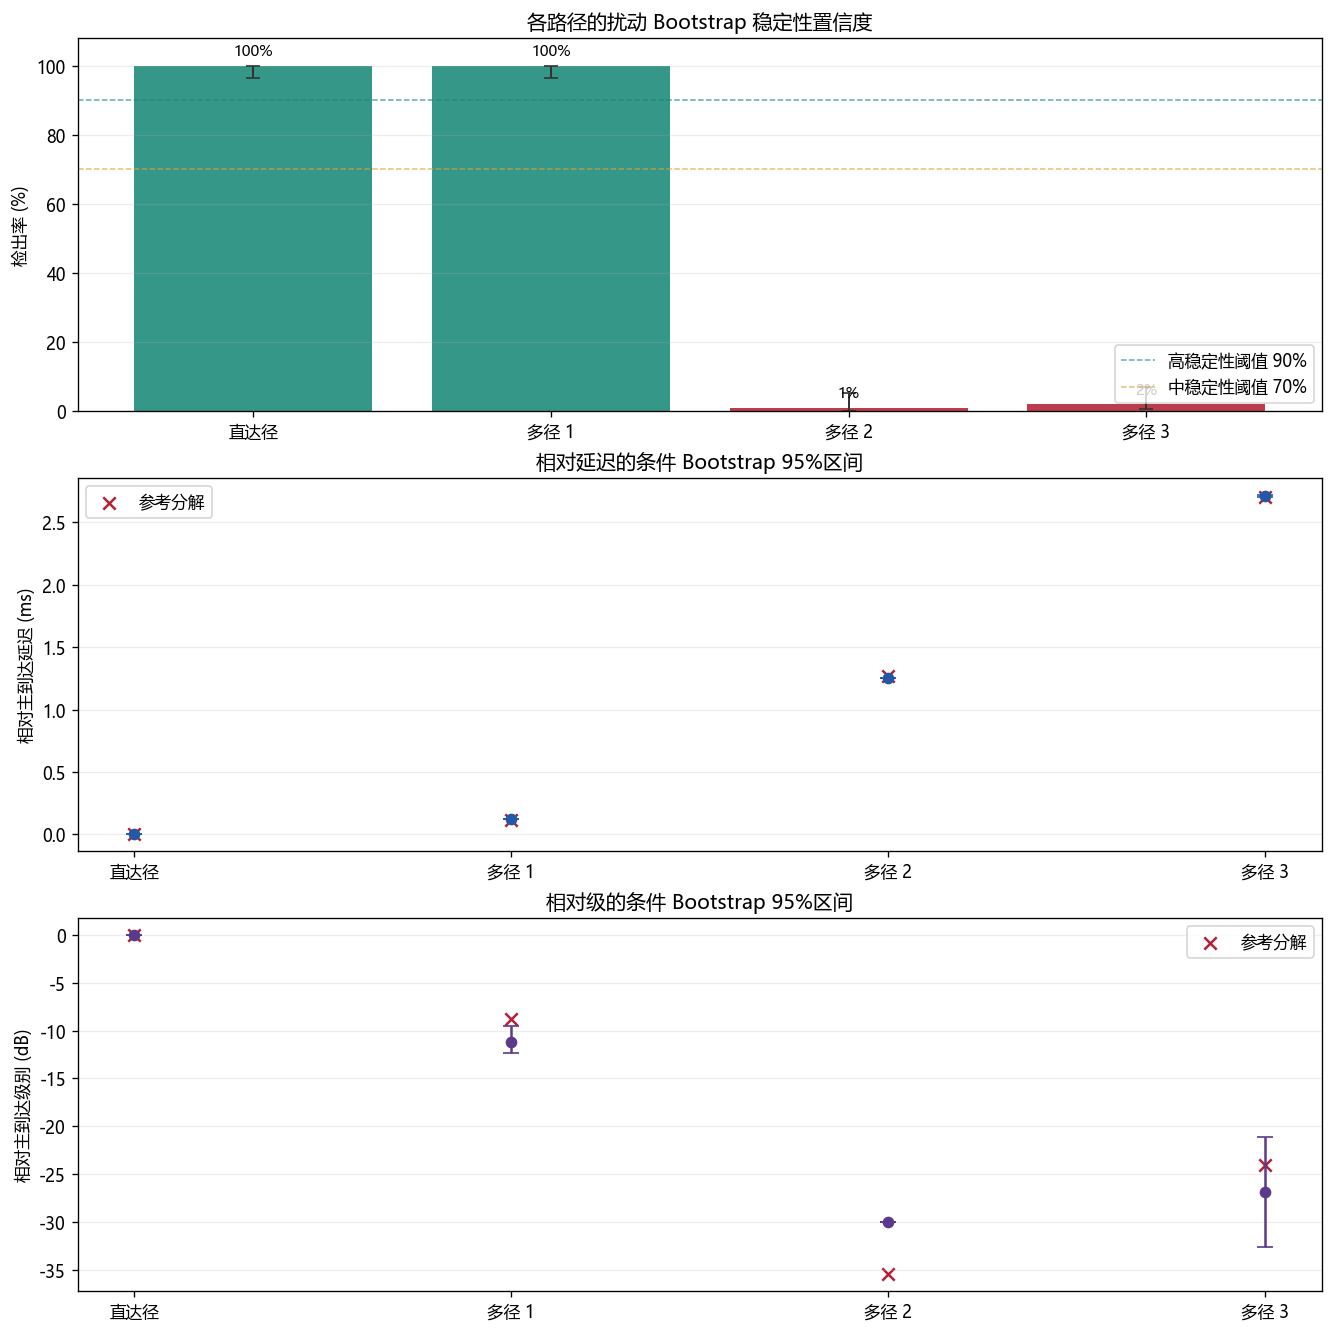

汇总 CSV：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\multipath_stability_confidence.csv
汇总 JSON：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\multipath_stability_confidence.json
运行参数 CSV：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\bootstrap_run_metadata.csv
置信度图：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\multipath_stability_confidence.png


In [7]:
csv_path = OUTPUT_DIR / "multipath_stability_confidence.csv"
json_path = OUTPUT_DIR / "multipath_stability_confidence.json"
metadata_path = OUTPUT_DIR / "bootstrap_run_metadata.csv"

with csv_path.open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(file, fieldnames=list(summary[0].keys()))
    writer.writeheader()
    writer.writerows(summary)

with metadata_path.open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(file, fieldnames=list(run_metadata[0].keys()))
    writer.writeheader()
    writer.writerows(run_metadata)

with json_path.open("w", encoding="utf-8") as file:
    json.dump({
        "record": "010 | Voyage_Ori_01 / PulseTrain_014 / Click_008",
        "definition": "扰动 Bootstrap 中在参考延迟 ±0.03 ms 内的重现率；不是物理真实性概率。",
        "settings": {
            "n_bootstrap": N_BOOTSTRAP,
            "lambda_perturbation": LAMBDA_PERTURBATION,
            "atom_duration_range_ms": ATOM_DURATION_RANGE_MS,
            "atom_duration_range_us": [value * 1e3 for value in ATOM_DURATION_RANGE_MS],
            "min_3db_bandwidth_khz": MIN_3DB_BANDWIDTH_HZ / 1e3,
            "max_3db_bandwidth_khz": MAX_3DB_BANDWIDTH_HZ / 1e3,
            "bandwidth_projection": "hard Gaussian spectral-envelope projection after every atom update",
            "match_tolerance_ms": MATCH_TOLERANCE_MS,
            "residual_block_ms": RESIDUAL_BLOCK_MS,
            "random_seed": RANDOM_SEED,
        },
        "reference_explained_variance": float(reference_explained),
        "reference_atom_duration_us": float(reference_atom_len / fs * 1e6),
        "reference_atom_3db_bandwidth_khz": float(reference_bandwidth_hz / 1e3),
        "bootstrap_bandwidth_min_khz": float(bootstrap_bandwidths_khz.min()),
        "bootstrap_bandwidth_max_khz": float(bootstrap_bandwidths_khz.max()),
        "bandwidth_constraint_pass_rate": 1.0,
        "mean_unmatched_candidates_per_run": float(np.mean(unmatched_counts)),
        "paths": summary,
    }, file, ensure_ascii=False, indent=2)

labels = ["直达径" if row["path"] == "direct" else row["path"].replace("multipath_", "多径 ") for row in summary]
confidence = np.array([row["stability_confidence"] for row in summary]) * 100
confidence_low = np.array([row["confidence_wilson_low"] for row in summary]) * 100
confidence_high = np.array([row["confidence_wilson_high"] for row in summary]) * 100
delay_median = np.array([row["delay_median_ms"] for row in summary])
delay_low = np.array([row["delay_ci_low_ms"] for row in summary])
delay_high = np.array([row["delay_ci_high_ms"] for row in summary])
level_median = np.array([row["level_median_db"] for row in summary])
level_low = np.array([row["level_ci_low_db"] for row in summary])
level_high = np.array([row["level_ci_high_db"] for row in summary])
x = np.arange(len(summary))
colors = ["#188977" if value >= 90 else "#E09F3E" if value >= 70 else "#B32134" for value in confidence]

fig, axes = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
axes[0].bar(x, confidence, color=colors, alpha=0.88)
axes[0].errorbar(
    x, confidence,
    yerr=np.vstack([confidence - confidence_low, confidence_high - confidence]),
    fmt="none", ecolor="0.2", capsize=4, lw=1.2,
)
for index, value in enumerate(confidence):
    axes[0].text(index, min(value + 2.0, 102), f"{value:.0f}%", ha="center", va="bottom", fontsize=9)
axes[0].axhline(90, color="#188977", ls="--", lw=0.9, alpha=0.7, label="高稳定性阈值 90%")
axes[0].axhline(70, color="#E09F3E", ls="--", lw=0.9, alpha=0.7, label="中稳定性阈值 70%")
axes[0].set(title="各路径的扰动 Bootstrap 稳定性置信度", ylabel="检出率 (%)", ylim=(0, 108))
axes[0].legend(loc="lower right")

valid_delay = np.isfinite(delay_median)
axes[1].errorbar(
    x[valid_delay], delay_median[valid_delay],
    yerr=np.vstack([
        delay_median[valid_delay] - delay_low[valid_delay],
        delay_high[valid_delay] - delay_median[valid_delay],
    ]),
    fmt="o", color="#2457A6", ecolor="#2457A6", capsize=5,
)
axes[1].scatter(x, [row["reference_delay_ms"] for row in summary], marker="x", s=55, color="#B32134", label="参考分解")
axes[1].set(title="相对延迟的条件 Bootstrap 95%区间", ylabel="相对主到达延迟 (ms)")
axes[1].legend()

valid_level = np.isfinite(level_median)
axes[2].errorbar(
    x[valid_level], level_median[valid_level],
    yerr=np.vstack([
        level_median[valid_level] - level_low[valid_level],
        level_high[valid_level] - level_median[valid_level],
    ]),
    fmt="o", color="#5B3A8C", ecolor="#5B3A8C", capsize=5,
)
axes[2].scatter(x, [row["reference_level_db"] for row in summary], marker="x", s=55, color="#B32134", label="参考分解")
axes[2].set(title="相对级的条件 Bootstrap 95%区间", ylabel="相对主到达级别 (dB)")
axes[2].legend()

for ax in axes:
    ax.set_xticks(x, labels)
    ax.grid(axis="y", alpha=0.22)

figure_path = OUTPUT_DIR / "multipath_stability_confidence.png"
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"汇总 CSV：{csv_path}")
print(f"汇总 JSON：{json_path}")
print(f"运行参数 CSV：{metadata_path}")
print(f"置信度图：{figure_path}")


## 7. 解释规则

- **高稳定性（≥90%）**：在当前噪声、原子长度和正则扰动范围内反复出现。
- **中稳定性（70%–90%）**：多数情况下出现，但对模型设定存在可见敏感性。
- **低稳定性（<70%）**：结果依赖参数或残差实现，应作为弱候选处理。

这些等级不校正模型失配，例如“同一原子表示全部反射路径”的假设。如果参考分解本身把 click 内部振铃误认为多径，高检出率只说明该结构稳定存在于模型分解中，不能单独证明其传播来源。

本次结果只接受最终原子时长为20–150 μs且实测 −3 dB带宽为6–72 kHz的运行；任何越界都会中止计算，而不会静默写入置信度。

## 8. 受约束参考原子的时域与频域形状

该图展示参考 BCSC 分解最终得到的单位范数原子。时域横轴以原子绝对主峰为零点；频域显示单边归一化幅度谱，并标记主谱峰、−3 dB阈值和主谱峰所属连续 −3 dB频带的左右边界。

这里的6–72 kHz约束针对的是**带宽数值**，不是把原子的频率范围固定在6–72 kHz。

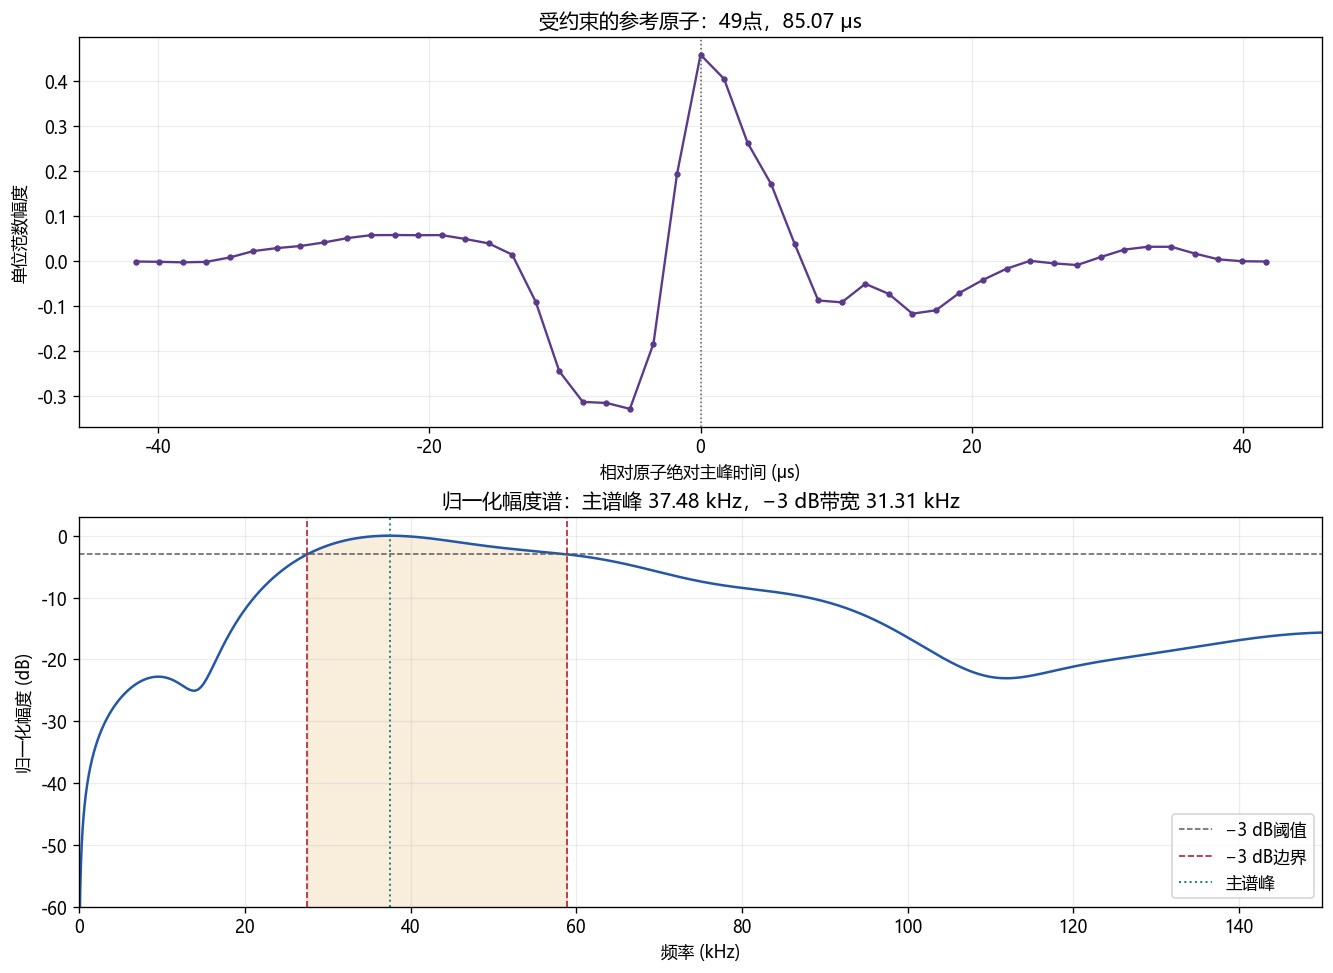

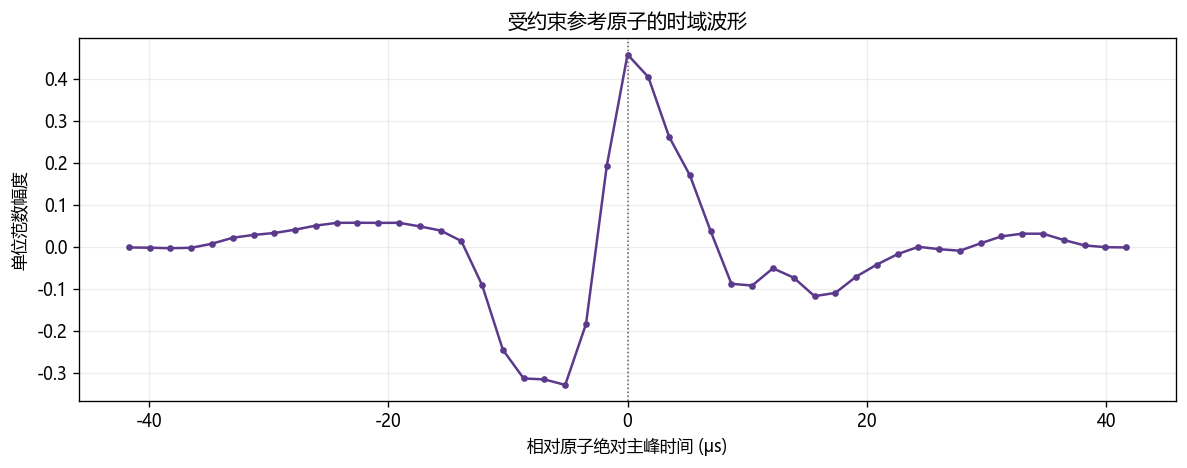

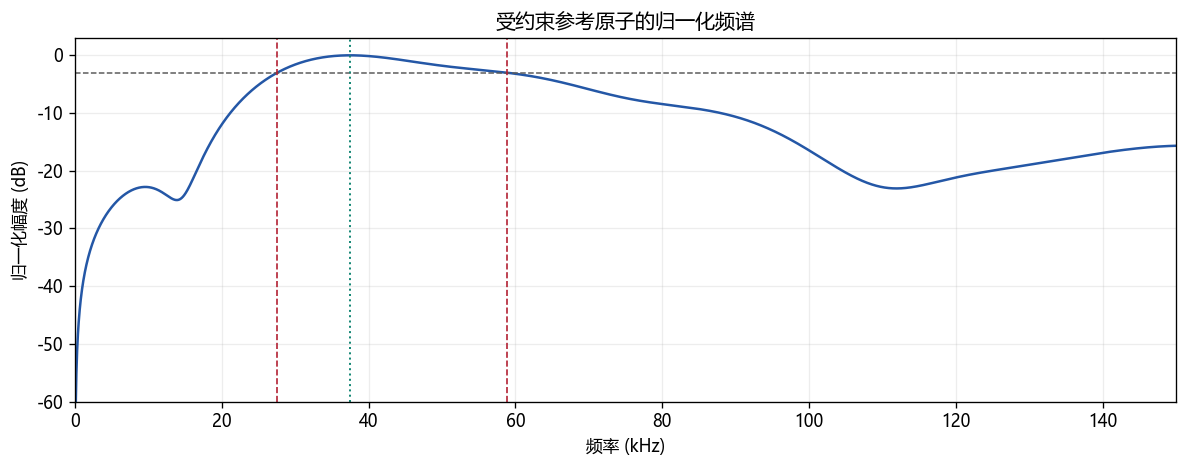

原子点数：49
原子时长：85.07 μs
主谱峰：37.48 kHz
−3 dB频带：27.54–58.85 kHz
−3 dB带宽：31.31 kHz
组合图：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\constrained_reference_atom_time_frequency.png
时域图：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\constrained_reference_atom_time.png
频谱图：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_010_bootstrap_confidence_results\constrained_reference_atom_spectrum.png


In [8]:
def spectrum_3db_details(atom, sample_rate, n_fft=16_384):
    magnitude = np.abs(np.fft.rfft(atom, n=n_fft))
    frequencies = np.fft.rfftfreq(n_fft, d=1.0 / sample_rate)
    magnitude_normalized = magnitude / (magnitude.max() + 1e-15)
    spectrum_db = 20.0 * np.log10(np.maximum(magnitude_normalized, 1e-8))
    peak_index = int(np.argmax(magnitude))
    threshold = 1.0 / np.sqrt(2.0)

    left = peak_index
    while left > 0 and magnitude_normalized[left - 1] >= threshold:
        left -= 1
    right = peak_index
    while right < len(magnitude_normalized) - 1 and magnitude_normalized[right + 1] >= threshold:
        right += 1

    def interpolate_crossing(i_below, i_above):
        f0, f1 = frequencies[i_below], frequencies[i_above]
        m0, m1 = magnitude_normalized[i_below], magnitude_normalized[i_above]
        return float(f0 + (threshold - m0) * (f1 - f0) / (m1 - m0 + 1e-15))

    left_hz = 0.0 if left == 0 else interpolate_crossing(left - 1, left)
    right_hz = sample_rate / 2.0 if right == len(magnitude_normalized) - 1 else interpolate_crossing(right + 1, right)
    return frequencies, spectrum_db, float(frequencies[peak_index]), left_hz, right_hz


atom_peak_index = int(np.argmax(np.abs(reference_atom)))
atom_time_us = (np.arange(len(reference_atom)) - atom_peak_index) / fs * 1e6
frequency_hz, atom_spectrum_db, peak_frequency_hz, left_3db_hz, right_3db_hz = spectrum_3db_details(
    reference_atom, fs, BANDWIDTH_NFFT
)
measured_bandwidth_hz = right_3db_hz - left_3db_hz

fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
axes[0].plot(atom_time_us, reference_atom, color="#5B3A8C", marker="o", ms=2.8, lw=1.4)
axes[0].axvline(0.0, color="0.35", ls=":", lw=0.9)
axes[0].set(
    title=f"受约束的参考原子：{len(reference_atom)}点，{len(reference_atom) / fs * 1e6:.2f} μs",
    xlabel="相对原子绝对主峰时间 (μs)",
    ylabel="单位范数幅度",
)

axes[1].plot(frequency_hz / 1e3, atom_spectrum_db, color="#2457A6", lw=1.5)
axes[1].axhline(-3.0, color="0.35", ls="--", lw=0.9, label="−3 dB阈值")
axes[1].axvline(left_3db_hz / 1e3, color="#B32134", ls="--", lw=1.0, label="−3 dB边界")
axes[1].axvline(right_3db_hz / 1e3, color="#B32134", ls="--", lw=1.0)
axes[1].axvline(peak_frequency_hz / 1e3, color="#188977", ls=":", lw=1.2, label="主谱峰")
axes[1].fill_between(
    frequency_hz / 1e3, -80, atom_spectrum_db,
    where=(frequency_hz >= left_3db_hz) & (frequency_hz <= right_3db_hz),
    color="#E09F3E", alpha=0.18,
)
axes[1].set(
    title=(f"归一化幅度谱：主谱峰 {peak_frequency_hz / 1e3:.2f} kHz，"
           f"−3 dB带宽 {measured_bandwidth_hz / 1e3:.2f} kHz"),
    xlabel="频率 (kHz)",
    ylabel="归一化幅度 (dB)",
    xlim=(0, min(fs / 2e3, 150)),
    ylim=(-60, 3),
)
axes[1].legend(loc="lower right")

for ax in axes:
    ax.grid(alpha=0.22)

combined_path = OUTPUT_DIR / "constrained_reference_atom_time_frequency.png"
fig.savefig(combined_path, dpi=220, bbox_inches="tight")
plt.show()

fig_time, ax = plt.subplots(figsize=(10, 4))
ax.plot(atom_time_us, reference_atom, color="#5B3A8C", marker="o", ms=3, lw=1.5)
ax.axvline(0.0, color="0.35", ls=":", lw=0.9)
ax.set(title="受约束参考原子的时域波形", xlabel="相对原子绝对主峰时间 (μs)", ylabel="单位范数幅度")
ax.grid(alpha=0.22)
fig_time.tight_layout()
time_path = OUTPUT_DIR / "constrained_reference_atom_time.png"
fig_time.savefig(time_path, dpi=220, bbox_inches="tight")
plt.show()

fig_frequency, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequency_hz / 1e3, atom_spectrum_db, color="#2457A6", lw=1.5)
ax.axhline(-3.0, color="0.35", ls="--", lw=0.9)
ax.axvline(left_3db_hz / 1e3, color="#B32134", ls="--", lw=1.0)
ax.axvline(right_3db_hz / 1e3, color="#B32134", ls="--", lw=1.0)
ax.axvline(peak_frequency_hz / 1e3, color="#188977", ls=":", lw=1.2)
ax.set(title="受约束参考原子的归一化频谱", xlabel="频率 (kHz)", ylabel="归一化幅度 (dB)",
       xlim=(0, min(fs / 2e3, 150)), ylim=(-60, 3))
ax.grid(alpha=0.22)
fig_frequency.tight_layout()
frequency_path = OUTPUT_DIR / "constrained_reference_atom_spectrum.png"
fig_frequency.savefig(frequency_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"原子点数：{len(reference_atom)}")
print(f"原子时长：{len(reference_atom) / fs * 1e6:.2f} μs")
print(f"主谱峰：{peak_frequency_hz / 1e3:.2f} kHz")
print(f"−3 dB频带：{left_3db_hz / 1e3:.2f}–{right_3db_hz / 1e3:.2f} kHz")
print(f"−3 dB带宽：{measured_bandwidth_hz / 1e3:.2f} kHz")
print(f"组合图：{combined_path}")
print(f"时域图：{time_path}")
print(f"频谱图：{frequency_path}")
